# 02 — Baselines Evaluation

Every run in the loop so far, parsed live from `runs/*.log`. Sprint protocol: fixed seed per round, 5-min wall-clock (or fixed steps where marked `round2s`), parameter-matched ~1.33M, identical data/LR/batch.

In [1]:
import sys, pathlib, glob, re, warnings
warnings.filterwarnings('ignore')
ROOT = pathlib.Path().resolve().parent
sys.path.insert(0, str(ROOT / 'paper'))
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
DEVICE = 'cpu'   # GPU reserved for the sprint queue; flip when free
torch.manual_seed(0)


In [2]:
from log_notebook import parse_log
def results_frame():
    rows = []
    for f in sorted(glob.glob(str(ROOT / 'runs' / 'round*_*.log'))):
        name = pathlib.Path(f).stem
        rnd, rest = name.split('_', 1)
        m = re.match(r'(.+?)_s(\d+)$', rest)
        variant, seed = (m.group(1), int(m.group(2))) if m else (rest, 1337)
        d = parse_log(f)
        if d['crashed']:
            continue
        rows.append(dict(round=rnd, variant=variant, seed=seed,
                         v1=float(d['val_vrmse_1']), v8=float(d['val_vrmse_8']),
                         steps=int(d['num_steps']), params=int(d['num_params'])))
    return pd.DataFrame(rows)
df = results_frame()
df.sort_values(['round','v8']).reset_index(drop=True)

,round,variant,seed,v1,v8,steps,params
0,round1,hea12,1337,0.404158,0.876266,6912,1334316
1,round1,ryd16,1337,0.432271,0.913071,2850,1335284
2,round1,hea16,1337,0.483141,1.099660,1872,1335244
3,round1,none,1337,0.419049,1.142565,10597,1331484
4,round1,mlp,1337,0.425023,1.212846,10326,1335212
5,round2,hea12f,1337,0.428904,1.044422,7270,1334316
6,round2,ryd12,1337,0.419900,1.167889,7772,1334348
7,round2s,hea12,1337,0.485632,1.325017,2500,1334316
8,round2s,hea16,1337,0.474597,1.507686,2500,1335244
9,round2s,none,1337,0.477027,2.102174,2500,1331484


## Round 1 — 5-minute wall-clock (throughput included)

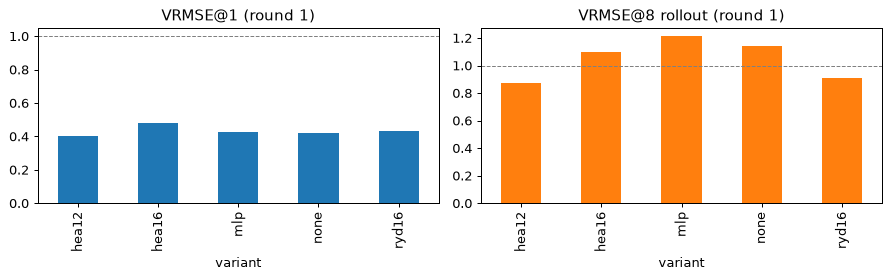

               v1        v8  steps
variant                           
hea12    0.404158  0.876266   6912
hea16    0.483141  1.099660   1872
mlp      0.425023  1.212846  10326
none     0.419049  1.142565  10597
ryd16    0.432271  0.913071   2850


In [3]:
r1 = df[df['round'] == 'round1'].set_index('variant')
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
r1['v1'].plot.bar(ax=ax[0], title='VRMSE@1 (round 1)')
r1['v8'].plot.bar(ax=ax[1], title='VRMSE@8 rollout (round 1)', color='tab:orange')
for a in ax: a.axhline(1.0, ls='--', c='gray', lw=.8)
plt.tight_layout(); plt.show()
print(r1[['v1','v8','steps']].to_string())

**Read:** `mlp` (matched classical control) is *worse* than no bottleneck at all — the round-1 quantum win (hea12, -23% rollout) is not a 'any bottleneck helps' artifact.

## Round 2s — fixed 2,500 steps (throughput removed)

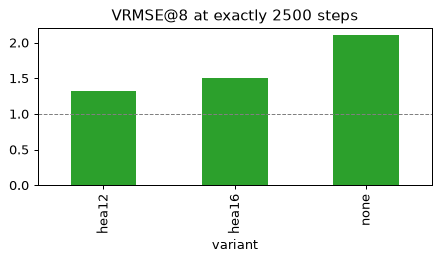

hea12    v8=1.325  vs none: -37.0%
hea16    v8=1.508  vs none: -28.3%
none     v8=2.102  vs none: +0.0%


In [4]:
r2s = df[df['round'] == 'round2s'].set_index('variant')
ax = r2s['v8'].plot.bar(figsize=(5, 3), color='tab:green',
                        title='VRMSE@8 at exactly 2500 steps')
ax.axhline(1.0, ls='--', c='gray', lw=.8)
plt.tight_layout(); plt.show()
base = r2s.loc['none', 'v8']
for v in r2s.index:
    print(f'{v:8s} v8={r2s.loc[v,"v8"]:.3f}  vs none: {100*(r2s.loc[v,"v8"]/base-1):+.1f}%')

**Read:** at equal gradient steps the 12q block cuts rollout error ~-37% — the quantum effect is per-step real, not a speed artifact. hea16 beats baseline but loses to hea12: digital-ansatz qubit scaling is NOT monotone. (The analog ansatz scaled the other way: ryd12 1.168 -> ryd16 0.913.)

## Run-to-run variance (honesty check)

In [5]:
h1 = df.query('round=="round1" and variant=="hea12"')['v8'].iloc[0]
h2 = df.query('round=="round2" and variant=="hea12f"')['v8'].iloc[0]
print(f'hea12 round1 {h1:.3f} vs math-equivalent fused rerun {h2:.3f}')
print(f'=> single-run sigma on v8 is roughly {abs(h1-h2):.2f} — single-seed')
print('   wins are NOT bankable; round 3 runs 3 seeds per variant.')

hea12 round1 0.876 vs math-equivalent fused rerun 1.044
=> single-run sigma on v8 is roughly 0.17 — single-seed
   wins are NOT bankable; round 3 runs 3 seeds per variant.


## Full ledger

In [6]:
df.sort_values(['round', 'variant', 'seed']).reset_index(drop=True)

,round,variant,seed,v1,v8,steps,params
0,round1,hea12,1337,0.404158,0.876266,6912,1334316
1,round1,hea16,1337,0.483141,1.099660,1872,1335244
2,round1,mlp,1337,0.425023,1.212846,10326,1335212
3,round1,none,1337,0.419049,1.142565,10597,1331484
4,round1,ryd16,1337,0.432271,0.913071,2850,1335284
5,round2,hea12f,1337,0.428904,1.044422,7270,1334316
6,round2,ryd12,1337,0.419900,1.167889,7772,1334348
7,round2s,hea12,1337,0.485632,1.325017,2500,1334316
8,round2s,hea16,1337,0.474597,1.507686,2500,1335244
9,round2s,none,1337,0.477027,2.102174,2500,1331484
